# Seasonal Agriculture Performance Analysis

**Domain:** Agriculture  
**Project Theme:** Seasonal Agriculture Performance  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Project Goal
Investigate how agricultural performance varies across seasons and identify meaningful patterns, trends, relationships and differences in the available data.


### Analytical Questions
1. How does agricultural performance vary across seasons?
2. Which season shows stronger yield and profitability?
3. How do crop performances differ within each season?
4. Are there noticeable differences in water use and water efficiency?
5. What relationships exist between environmental/resource variables and agricultural outcomes?
6. Which crop-season combinations show unusually high or low performance?
7. Where is profitability risk concentrated?


## 1. Problem Statement

Agricultural activities are influenced by seasonal variations in environmental conditions, farming practices, resource availability and economic conditions. As a result, agricultural performance may differ from one season to another.

The objective of this project is to analyze the given agricultural dataset and investigate seasonal differences in agricultural performance by identifying meaningful patterns, trends, relationships and variations within the available data.


## 2. Project Objectives

- Understand the structure and quality of the agricultural dataset.
- Clean and prepare the data for analysis.
- Explore seasonal patterns.
- Perform descriptive and statistical analysis.
- Investigate relationships among relevant variables.
- Compare agricultural performance across seasons and meaningful groups.
- Use appropriate univariate, bivariate and multivariate visualizations.
- Identify significant findings from the data.
- Develop evidence-based insights and recommendations.


## 3. Import Libraries

In [241]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 4. Load the Dataset




In [242]:
# Load the dataset

df = pd.read_csv("seasonal_agriculture_performance_dataset (3).csv")

print("Dataset loaded successfully.")


Dataset loaded successfully.


## 5. Initial Data Understanding

In [243]:
# Dataset shape

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 4000
Number of columns: 28


In [244]:
# Top 5 rows

df.head(5)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [245]:
# Bottom 5 rows

df.tail(5)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
3995,SF13996,Karnataka,Rajkot,Wheat,Kharif,4.72,865.4,27.3,51.4,6.3,...,0.74,0.51,2.41,22717,362917,54748,-308169,2016,1.195,45.2
3996,SF13997,Karnataka,Krishna,Chilli,Kharif,8.77,947.5,29.2,85.5,6.1,...,0.80,2.75,24.12,106459,496471,2567791,2071320,5351,4.508,59.7
3997,SF13998,Andhra Pradesh,Erode,Pulses,Zaid,10.47,80.0,35.4,68.5,8.6,...,0.99,0.62,6.49,66860,785632,433921,-351711,3392,1.913,29.2
3998,SF13999,Punjab,Warangal,Cotton,Kharif,1.73,475.0,28.2,61.7,6.4,...,0.98,1.35,2.34,75282,153904,176160,22256,1220,1.918,50.4
3999,SF14000,Punjab,Nashik,Wheat,Kharif,3.31,984.3,25.8,77.2,5.9,...,0.99,2.36,7.81,28812,263872,225022,-38850,1800,4.339,62.3


In [246]:
# Random sample of records

df.sample(5, random_state=42)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
555,SF10556,Andhra Pradesh,Nashik,Chilli,Rabi,7.94,456.8,25.3,47.7,7.6,...,0.87,NaN,15.64,92892,619157,1452831,833674,6146,2.545,34.4
3491,SF13492,Punjab,Warangal,Wheat,Kharif,12.44,601.9,27.2,60.2,8.3,...,0.77,0.94,11.69,23614,680562,276048,-404514,5818,2.009,31.8
527,SF10528,Maharashtra,Indore,Cotton,Kharif,6.35,1213.7,26.3,73.6,7.1,...,0.69,1.17,7.43,69828,441813,518822,77009,4491,1.654,52.7
3925,SF13926,Madhya Pradesh,Nashik,Wheat,Rabi,12.52,374.0,17.9,59.7,9.4,...,0.71,0.88,11.02,26649,744970,293672,-451298,3347,3.293,29.8
2989,SF12990,Gujarat,Rajkot,Chilli,Rabi,13.98,197.8,19.0,55.8,9.2,...,0.95,1.07,14.96,108549,994707,1623893,629186,10975,1.363,39.6


In [247]:
# Column names

print(df.columns.tolist())


['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method', 'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct']


In [248]:
# Data types and non-null counts

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [249]:
# Numerical summary statistics

df.describe()


,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,4000.000000,3960.000000,4000.000000,4000.000000,4000.000000,...,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
mean,7.888265,601.152657,26.81890,63.210500,7.323050,6.701010,26.508232,120.250825,57.781850,104.760050,...,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,4.223764,288.925025,3.81818,11.960834,1.121186,0.641461,6.712484,31.216452,17.015074,27.742681,...,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,0.500000,80.000000,16.20000,25.000000,3.500000,5.200000,8.000000,40.000000,15.000000,30.000000,...,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,4.260000,370.200000,23.90000,54.775000,6.600000,6.260000,21.700000,98.500000,46.200000,86.200000,...,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,7.895000,582.000000,26.90000,63.000000,7.300000,6.690000,26.400000,120.100000,57.500000,105.100000,...,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,11.650000,834.950000,29.60000,71.900000,8.100000,7.140000,31.300000,141.225000,69.400000,123.600000,...,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000
max,15.000000,1395.200000,39.70000,95.000000,11.000000,8.400000,47.000000,220.000000,120.000000,200.000000,...,1.000000,101.440000,1424.400000,131240.000000,1.349990e+06,5.080900e+06,4.345421e+06,40902.000000,79.800000,88.900000


In [250]:
# Categorical summary statistics

df.describe(include="str")


,Farm_ID,State,District,Crop,Season,Irrigation_Method
count,4000,4000,4000,4000,4000,4000
unique,4000,8,10,8,3,4
top,SF10001,Andhra Pradesh,Ludhiana,Rice,Kharif,Flood
freq,1,529,427,690,1779,1310


## 6. Data Quality Analysis

To investigate missing values, duplicate records, data types and unusual categorical values.




In [251]:
# Missing values

missing = df.isnull().sum().sort_values(ascending=False)
missing_percentage = (df.isnull().mean() * 100).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_percentage.round(2)
})

missing_summary[missing_summary["Missing_Count"] > 0]


,Missing_Count,Missing_Percentage
Rainfall_mm,48,1.2
Soil_Moisture_pct,40,1.0
Yield_Tonnes_Ha,32,0.8


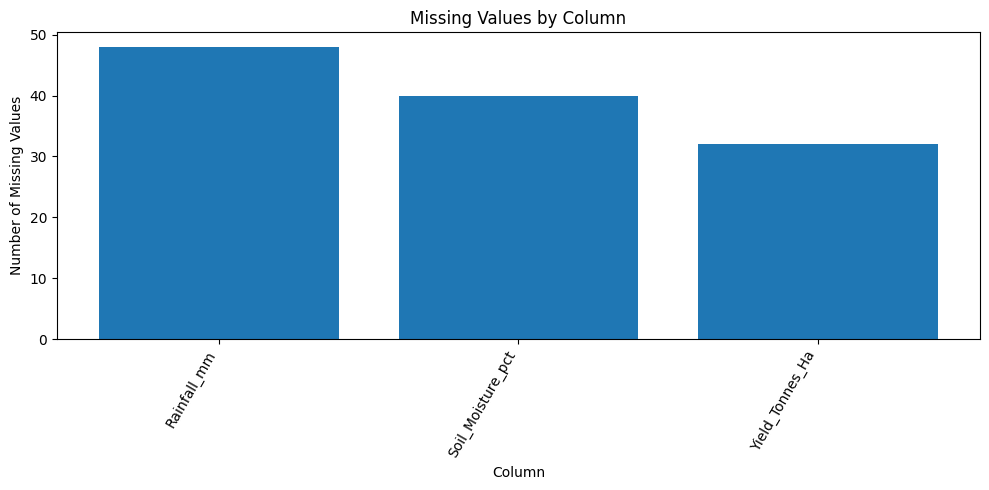

In [252]:
# Visualize missing values

missing_plot = missing[missing > 0]

if len(missing_plot) > 0:
    plt.figure(figsize=(10, 5))
    plt.bar(missing_plot.index, missing_plot.values)
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


In [253]:
# Duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate rows found. No removal is required.")
else:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed.")
    print("Shape after removing duplicates:", df.shape)


Number of duplicate rows: 0
No duplicate rows found. No removal is required.


In [254]:
# Check categorical values

categorical_columns = df.select_dtypes(include="str").columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].dropna().unique())
    print("Number of unique values:", df[col].nunique())



 Farm_ID
<StringArray>
['SF10001', 'SF10002', 'SF10003', 'SF10004', 'SF10005', 'SF10006', 'SF10007',
 'SF10008', 'SF10009', 'SF10010',
 ...
 'SF13991', 'SF13992', 'SF13993', 'SF13994', 'SF13995', 'SF13996', 'SF13997',
 'SF13998', 'SF13999', 'SF14000']
Length: 4000, dtype: str
Number of unique values: 4000

 State
<StringArray>
['Andhra Pradesh',    'Maharashtra',      'Telangana',      'Karnataka',
        'Gujarat',     'Tamil Nadu',         'Punjab', 'Madhya Pradesh']
Length: 8, dtype: str
Number of unique values: 8

 District
<StringArray>
[  'Rajkot', 'Nalgonda', 'Warangal',   'Indore', 'Ludhiana',  'Raichur',
   'Guntur',  'Krishna',   'Nashik',    'Erode']
Length: 10, dtype: str
Number of unique values: 10

 Crop
<StringArray>
[    'Wheat',     'Maize',    'Pulses',      'Rice',    'Cotton',    'Chilli',
 'Groundnut', 'Sugarcane']
Length: 8, dtype: str
Number of unique values: 8

 Season
<StringArray>
['Kharif', 'Rabi', 'Zaid']
Length: 3, dtype: str
Number of unique values: 3

 

## 7. Missing Value Treatment

Only numerical columns with missing values are treated here. Median imputation is appropriate for this project because it preserves the existing observations and is less affected by extreme values than the mean.

Missing values are **not** blindly replaced with zero.


In [255]:
# Fill missing numerical values using the median

numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("Remaining missing values:", df.isnull().sum().sum())


Remaining missing values: 0


## 8. Feature / Variable Review

The dataset contains both categorical and numerical variables.

Typical categorical variables include `Farm_ID`, `State`, `District`, `Crop`, `Season` and `Irrigation_Method`.

Numerical variables include environmental conditions, soil/input measures, production, market price, costs, revenue, profit, water usage, water efficiency and disease/pest risk.


In [256]:
# Numerical columns

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical columns:", len(numeric_columns))
print(numeric_columns)


Number of numerical columns: 22
['Farm_Area_Hectares', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct']


In [257]:
# Categorical columns

categorical_columns = df.select_dtypes(include="str").columns.tolist()

print("Number of categorical columns:", len(categorical_columns))
print(categorical_columns)


Number of categorical columns: 6
['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Irrigation_Method']


## 9. Descriptive and Statistical Analysis

In [258]:
# Descriptive statistics for important performance variables

performance_columns = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Profit_INR",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Disease_Pest_Risk_pct"
]

df[performance_columns].describe().round(2)


,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00
mean,5.24,43.25,44714.17,526303.58,637860.05,111556.46,6045.57,5.39,46.37
std,13.31,126.88,30266.16,294419.14,636974.71,545081.89,5572.94,8.84,12.42
min,0.30,0.15,2594.00,26826.00,6107.00,-1019223.00,128.00,0.14,5.00
25%,1.05,5.02,21429.25,274577.50,207517.25,-148731.75,2268.75,1.66,37.30
50%,1.74,11.77,25913.00,519082.50,456830.50,3673.00,4435.00,2.94,46.40
75%,2.83,24.36,68279.00,761996.50,836874.75,216187.75,7829.75,5.15,54.90
max,101.44,1424.40,131240.00,1349990.00,5080900.00,4345421.00,40902.00,79.80,88.90


In [259]:
# Mean, median, standard deviation, range and IQR

statistics = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Standard_Deviation": df[numeric_columns].std(),
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max(),
    "Range": df[numeric_columns].max() - df[numeric_columns].min(),
    "IQR": df[numeric_columns].quantile(0.75) - df[numeric_columns].quantile(0.25)
})

statistics.round(2)


,Mean,Median,Standard_Deviation,Minimum,Maximum,Range,IQR
Farm_Area_Hectares,7.89,7.90,4.22,0.50,15.00,14.50,7.39
Rainfall_mm,600.92,582.00,287.19,80.00,1395.20,1315.20,460.40
Avg_Temperature_C,26.82,26.90,3.82,16.20,39.70,23.50,5.70
Humidity_pct,63.21,63.00,11.96,25.00,95.00,70.00,17.13
Sunlight_Hours_Day,7.32,7.30,1.12,3.50,11.00,7.50,1.50
Soil_pH,6.70,6.69,0.64,5.20,8.40,3.20,0.88
Soil_Moisture_pct,26.51,26.40,6.68,8.00,47.00,39.00,9.40
Nitrogen_kg_ha,120.25,120.10,31.22,40.00,220.00,180.00,42.72
Phosphorus_kg_ha,57.78,57.50,17.02,15.00,120.00,105.00,23.20
Potassium_kg_ha,104.76,105.10,27.74,30.00,200.00,170.00,37.40


## 10. Outlier Investigation

Outliers are investigated using the IQR method. They are not automatically deleted because an unusual agricultural observation may represent a genuine farm-level condition.


In [260]:
# IQR-based outlier counts

outlier_summary = []

for col in performance_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append([col, lower, upper, count])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=["Column", "Lower_Bound", "Upper_Bound", "Outlier_Count"]
)

outlier_summary


,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Yield_Tonnes_Ha,-1.620000,5.500000e+00,302
1,Production_Tonnes,-23.982500,5.335750e+01,333
2,Market_Price_INR_Tonne,-48845.375000,1.385536e+05,0
3,Total_Cost_INR,-456551.000000,1.493125e+06,0
4,Revenue_INR,-736519.000000,1.780911e+06,240
5,Profit_INR,-696111.000000,7.635670e+05,404
6,Water_Used_m3,-6072.750000,1.617125e+04,276
7,Water_Efficiency_t_per_1000m3,-3.572875,1.038412e+01,322
8,Disease_Pest_Risk_pct,10.900000,8.130000e+01,10


## 11. Univariate Analysis

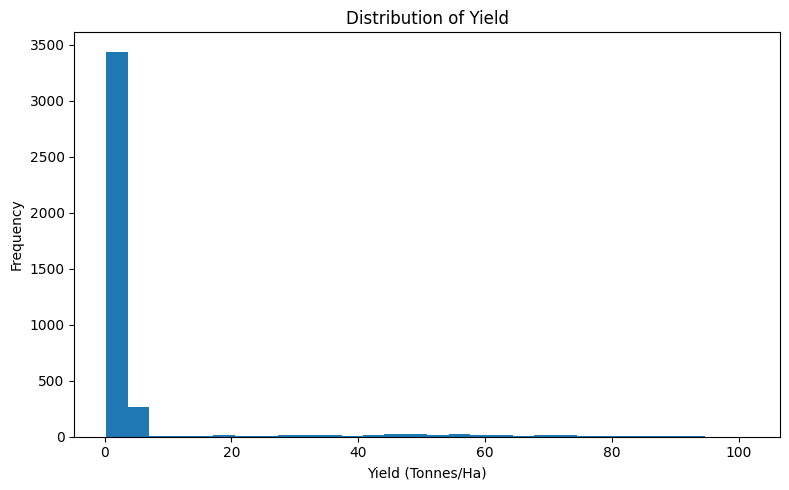

In [261]:
# Distribution of Yield

plt.figure(figsize=(8, 5))
plt.hist(df["Yield_Tonnes_Ha"], bins=30)
plt.title("Distribution of Yield")
plt.xlabel("Yield (Tonnes/Ha)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


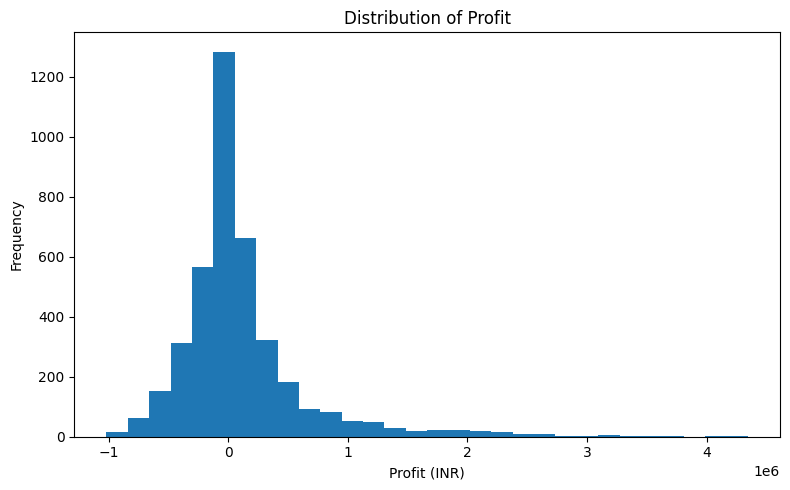

In [262]:
# Distribution of Profit

plt.figure(figsize=(8, 5))
plt.hist(df["Profit_INR"], bins=30)
plt.title("Distribution of Profit")
plt.xlabel("Profit (INR)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


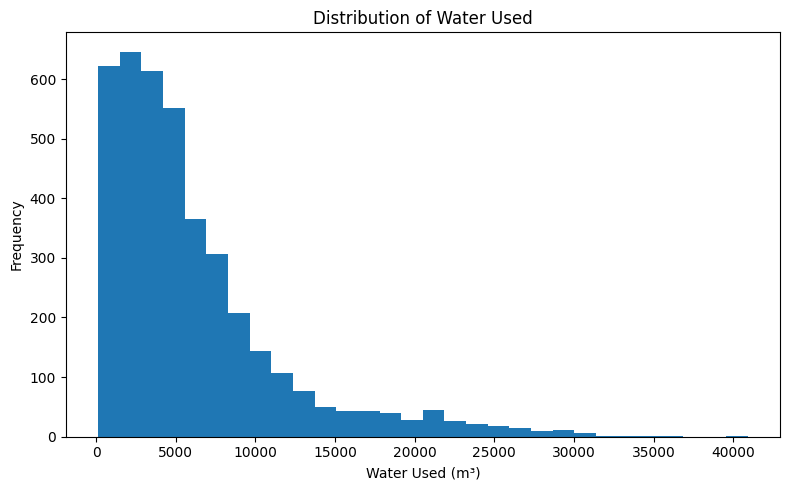

In [263]:
# Distribution of Water Used

plt.figure(figsize=(8, 5))
plt.hist(df["Water_Used_m3"], bins=30)
plt.title("Distribution of Water Used")
plt.xlabel("Water Used (m³)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


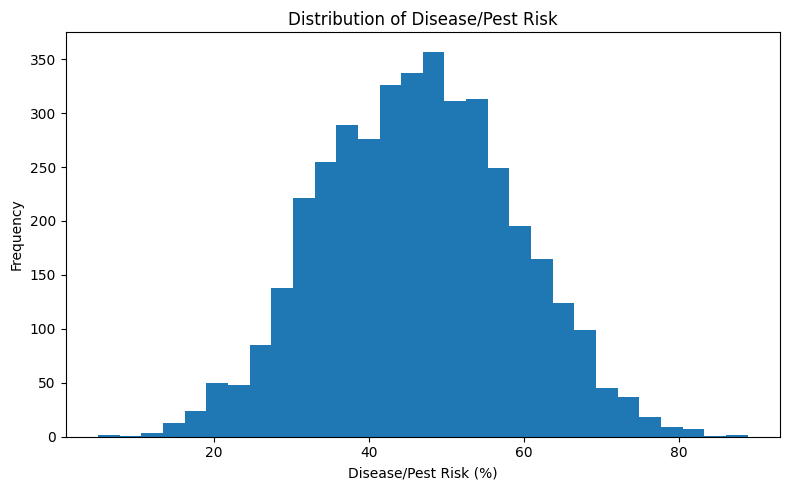

In [264]:
# Distribution of Disease/Pest Risk

plt.figure(figsize=(8, 5))
plt.hist(df["Disease_Pest_Risk_pct"], bins=30)
plt.title("Distribution of Disease/Pest Risk")
plt.xlabel("Disease/Pest Risk (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


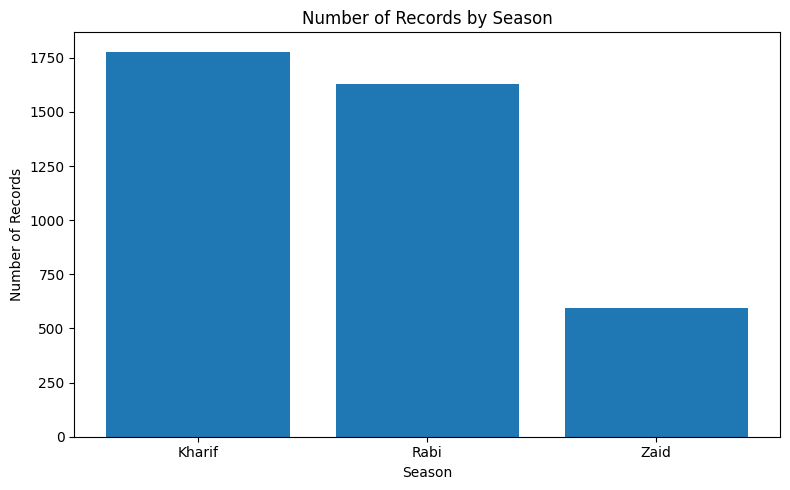

In [265]:
# Number of records by season

season_counts = df["Season"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(season_counts.index, season_counts.values)
plt.title("Number of Records by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


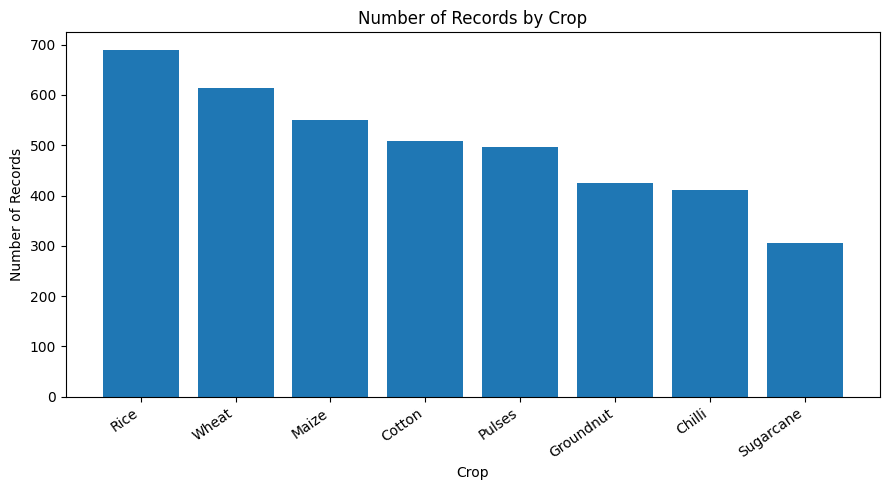

In [266]:
# Number of records by crop

crop_counts = df["Crop"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(crop_counts.index, crop_counts.values)
plt.title("Number of Records by Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 12. Bivariate Analysis

Bivariate analysis examines relationships between two variables or compares one numerical variable across categories.

The analysis below covers:
- Season vs yield
- Season vs profit
- Season vs water use
- Rainfall vs yield
- Farm area vs production
- Irrigation method vs yield

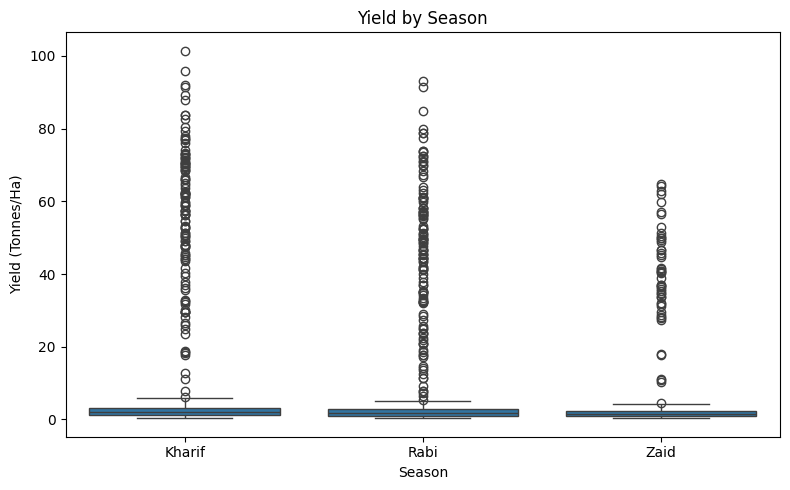

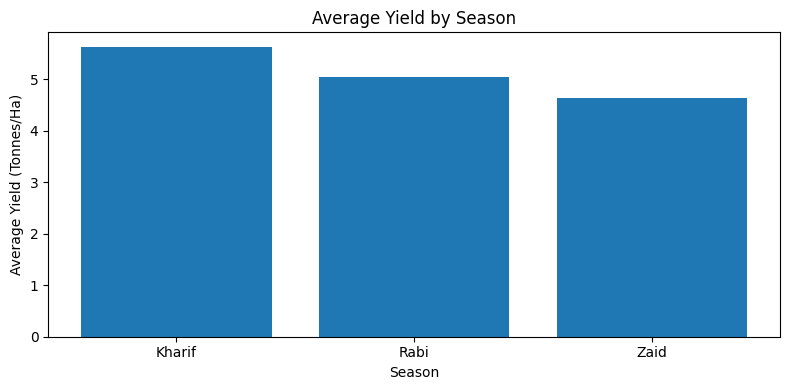

In [267]:
# Season vs Yield

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Season", y="Yield_Tonnes_Ha")
plt.title("Yield by Season")
plt.xlabel("Season")
plt.ylabel("Yield (Tonnes/Ha)")
plt.tight_layout()
plt.show()

# Average yield by season

avg_yield = df.groupby("Season")["Yield_Tonnes_Ha"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(avg_yield.index, avg_yield.values)
plt.title("Average Yield by Season")
plt.xlabel("Season")
plt.ylabel("Average Yield (Tonnes/Ha)")
plt.tight_layout()
plt.show()

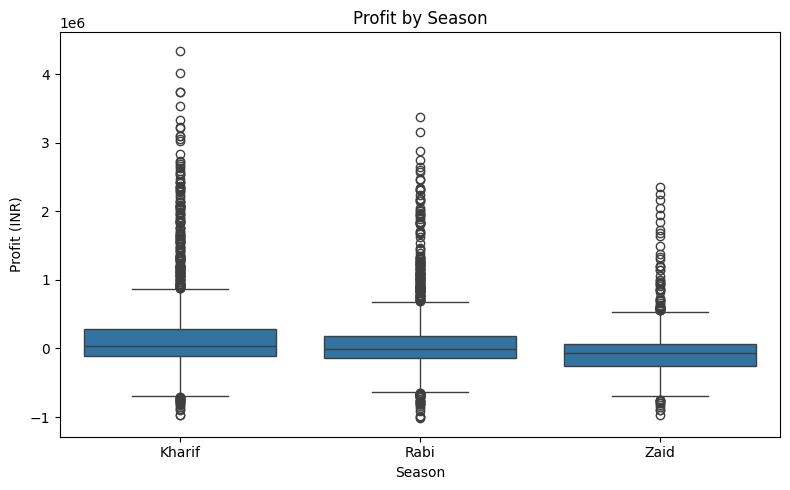

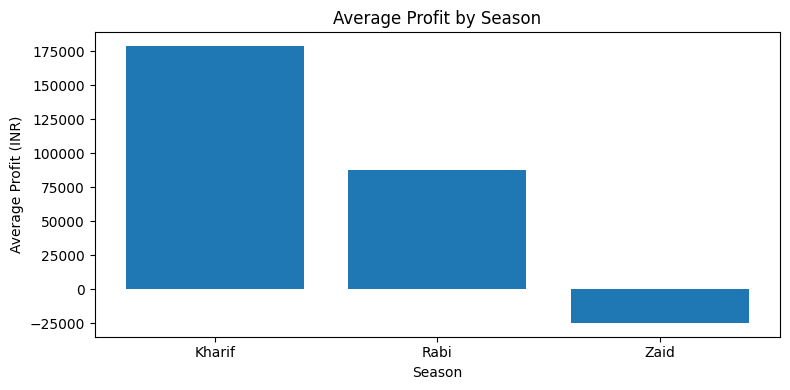

In [268]:
# Season vs Profit

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Season", y="Profit_INR")
plt.title("Profit by Season")
plt.xlabel("Season")
plt.ylabel("Profit (INR)")
plt.tight_layout()
plt.show()

# Average profit by season

avg_profit = df.groupby("Season")["Profit_INR"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(avg_profit.index, avg_profit.values)
plt.title("Average Profit by Season")
plt.xlabel("Season")
plt.ylabel("Average Profit (INR)")
plt.tight_layout()
plt.show()

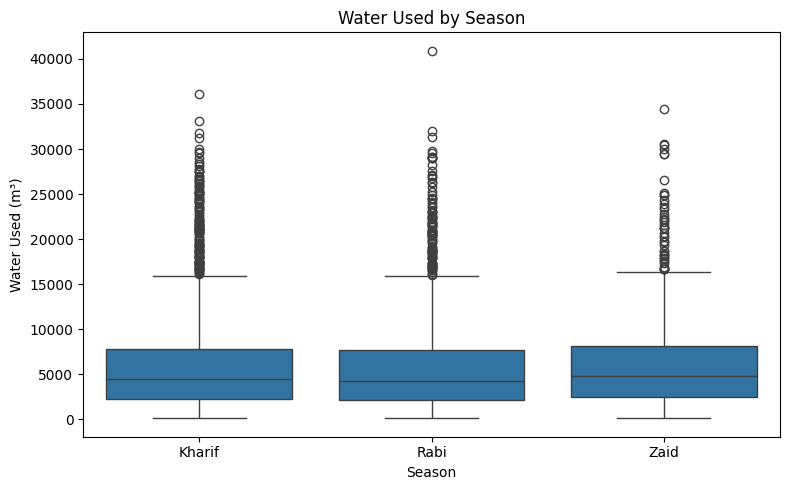

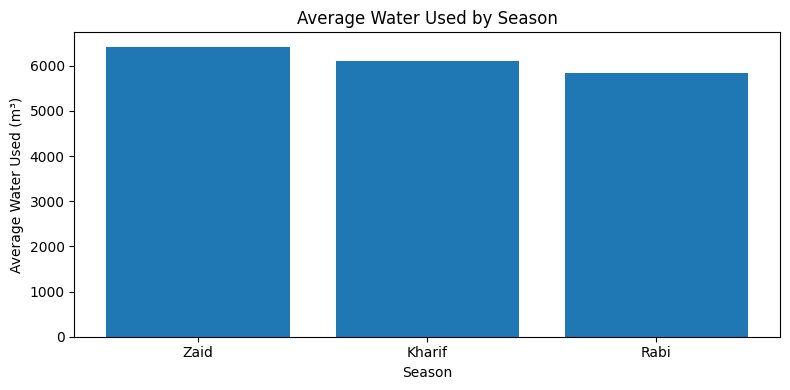

In [269]:
# Season vs Water Used

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Season", y="Water_Used_m3")
plt.title("Water Used by Season")
plt.xlabel("Season")
plt.ylabel("Water Used (m³)")
plt.tight_layout()
plt.show()

# Average water used by season

avg_water = df.groupby("Season")["Water_Used_m3"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(avg_water.index, avg_water.values)
plt.title("Average Water Used by Season")
plt.xlabel("Season")
plt.ylabel("Average Water Used (m³)")
plt.tight_layout()
plt.show()

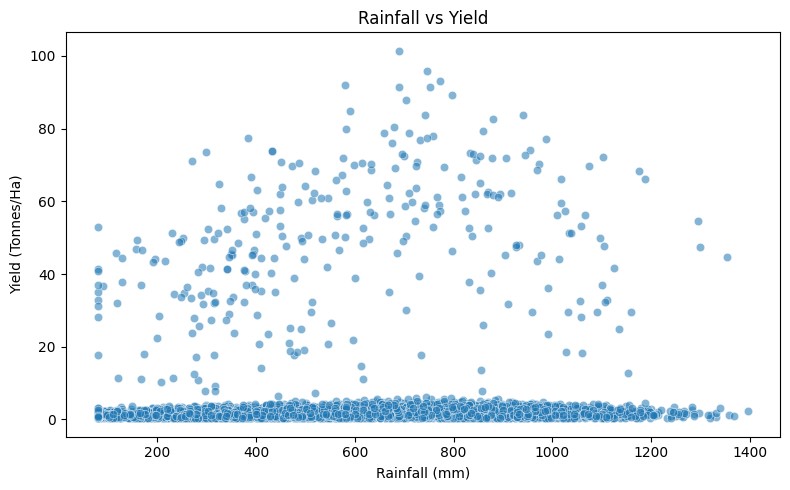

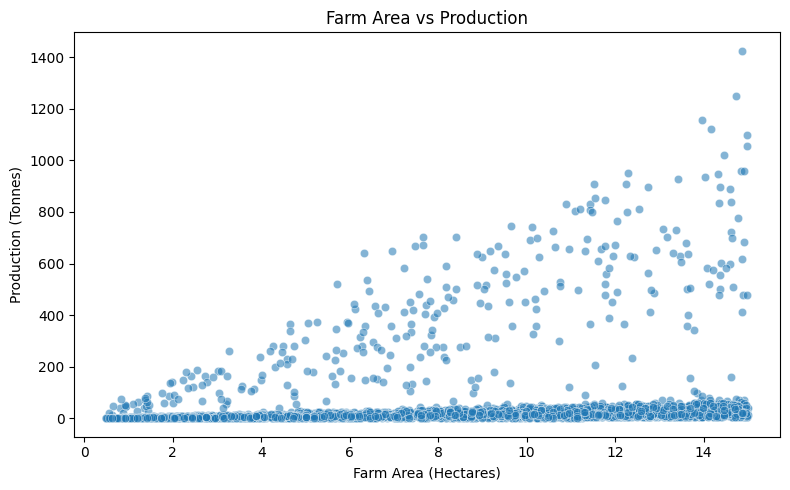

In [270]:
# Rainfall vs Yield

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Rainfall_mm", y="Yield_Tonnes_Ha", alpha=0.55)
plt.title("Rainfall vs Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (Tonnes/Ha)")
plt.tight_layout()
plt.show()

# Farm Area vs Production

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Farm_Area_Hectares", y="Production_Tonnes", alpha=0.55)
plt.title("Farm Area vs Production")
plt.xlabel("Farm Area (Hectares)")
plt.ylabel("Production (Tonnes)")
plt.tight_layout()
plt.show()

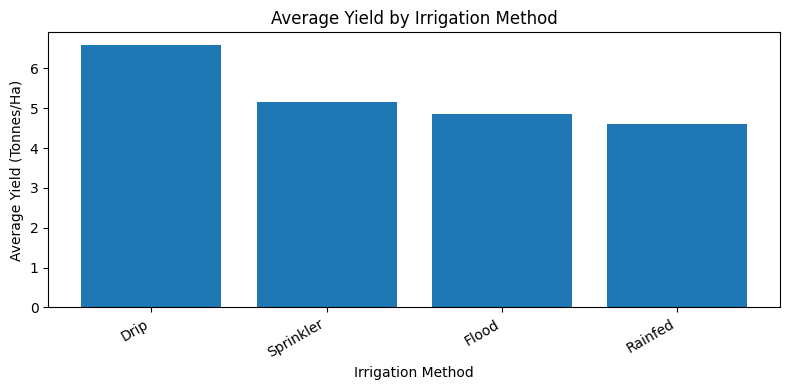

,Average_Yield
Irrigation_Method,
Drip,6.58
Sprinkler,5.16
Flood,4.86
Rainfed,4.60


In [271]:
# Irrigation Method vs Yield

irrigation_yield = (
    df.groupby("Irrigation_Method")["Yield_Tonnes_Ha"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 4))
plt.bar(irrigation_yield.index, irrigation_yield.values)
plt.title("Average Yield by Irrigation Method")
plt.xlabel("Irrigation Method")
plt.ylabel("Average Yield (Tonnes/Ha)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

display(irrigation_yield.to_frame("Average_Yield").round(2))

## 13. Multivariate Analysis

Agricultural performance is influenced by multiple dimensions at once. Multivariate views help compare crop, season, environmental and resource variables together.

In [272]:
# Crop × Season performance summary

crop_season_summary = df.groupby(["Season", "Crop"]).agg(
    Records=("Farm_ID", "count"),
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Average_Profit=("Profit_INR", "mean"),
    Average_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Average_Risk=("Disease_Pest_Risk_pct", "mean")
).round(2).sort_values(
    ["Season", "Average_Yield"],
    ascending=[True, False]
)

display(crop_season_summary)

Records  Average_Yield  Average_Profit  \
Season Crop                                                
Kharif Sugarcane      125          53.46      1000790.81   
       Maize          234           2.97       -39332.67   
       Rice           314           2.70       -64903.40   
       Wheat          292           2.25      -105871.87   
       Chilli         185           1.73       954380.42   
       Groundnut      193           1.48       108265.44   
       Cotton         215           1.37       216999.55   
       Pulses         221           1.04        43338.90   
Rabi   Sugarcane      129          43.29       731612.86   
       Maize          233           2.60       -89133.40   
       Rice           274           2.32       -98427.87   
       Wheat          237           2.06      -119954.57   
       Chilli         163           1.47       638572.50   
       Groundnut      177           1.23        10416.54   
       Cotton         201           1.20       107343.59   
       Pulses         213           0.88       -14309.14   
Zaid   Sugarcane       51          38.42       583635.80   
       Maize           84           2.29      -194049.17   
       Rice           102           1.90      -227239.34   
       Wheat           85           1.75      -193208.95   
       Chilli          64           1.20       448659.09   
       Groundnut       54           1.04       -68872.50   
       Cotton          92           0.96       -53925.34   
       Pulses          62           0.67      -139227.81   

                  Average_Water_Efficiency  Average_Risk  
Season Crop                                               
Kharif Sugarcane                     36.00         54.02  
       Maize                          6.05         54.82  
       Rice                           2.17         54.25  
       Wheat                          4.76         55.58  
       Chilli                         3.26         52.81  
       Groundnut                      3.58         54.28  
       Cotton                         2.13         54.24  
       Pulses                         3.35         54.96  
Rabi   Sugarcane                     27.92         39.85  
       Maize                          5.46         39.41  
       Rice                           1.84         40.79  
       Wheat                          4.69         41.46  
       Chilli                         2.89         40.59  
       Groundnut                      2.90         39.76  
       Cotton                         1.94         41.54  
       Pulses                         2.70         40.08  
Zaid   Sugarcane                     23.39         38.35  
       Maize                          4.75         36.68  
       Rice                           1.53         37.95  
       Wheat                          4.02         39.16  
       Chilli                         2.20         40.50  
       Groundnut                      2.47         39.13  
       Cotton                         1.49         36.34  
       Pulses                         1.95         38.97

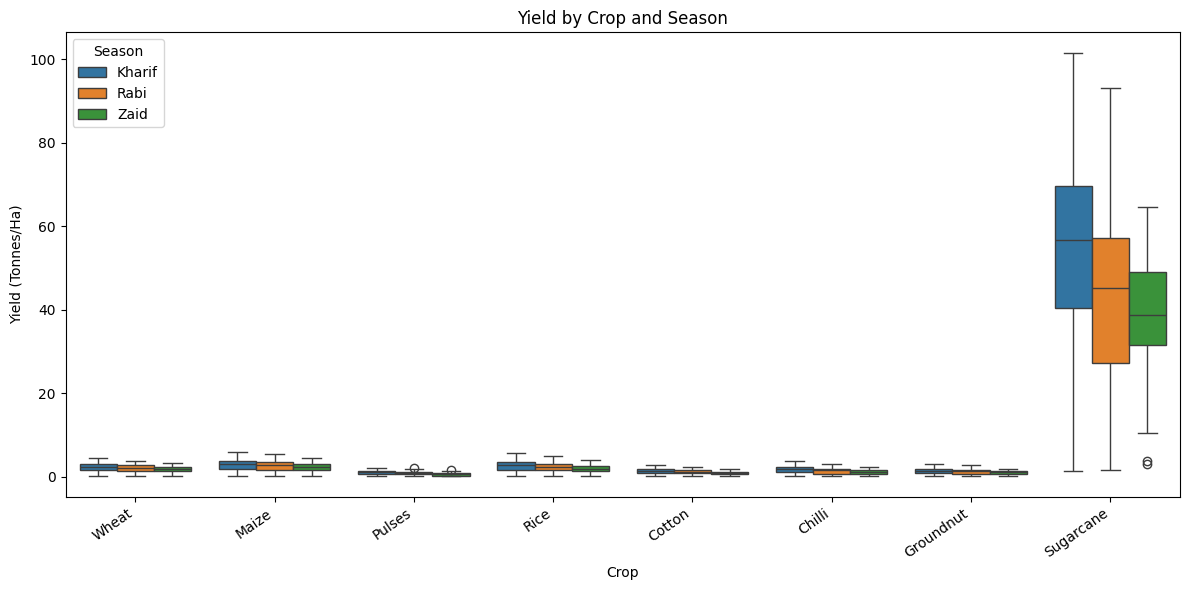

In [273]:
# Crop × Season yield visualization

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Crop", y="Yield_Tonnes_Ha", hue="Season")
plt.title("Yield by Crop and Season")
plt.xlabel("Crop")
plt.ylabel("Yield (Tonnes/Ha)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

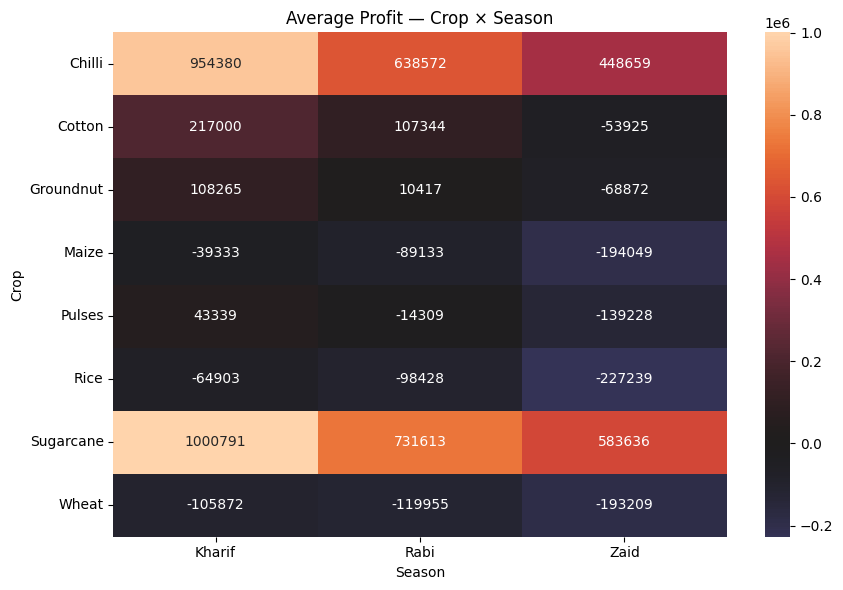

In [274]:
# Crop × Season average profit matrix

profit_pivot = df.pivot_table(
    index="Crop",
    columns="Season",
    values="Profit_INR",
    aggfunc="mean"
)

plt.figure(figsize=(9, 6))
sns.heatmap(profit_pivot, annot=True, fmt=".0f", center=0)
plt.title("Average Profit — Crop × Season")
plt.xlabel("Season")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

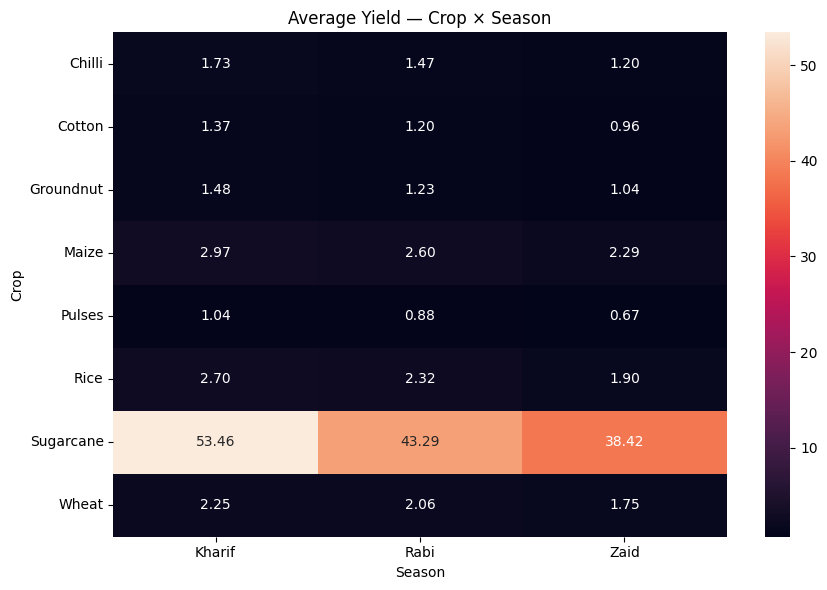

In [275]:
# Crop × Season average yield matrix

yield_pivot = df.pivot_table(
    index="Crop",
    columns="Season",
    values="Yield_Tonnes_Ha",
    aggfunc="mean"
)

plt.figure(figsize=(9, 6))
sns.heatmap(yield_pivot, annot=True, fmt=".2f")
plt.title("Average Yield — Crop × Season")
plt.xlabel("Season")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

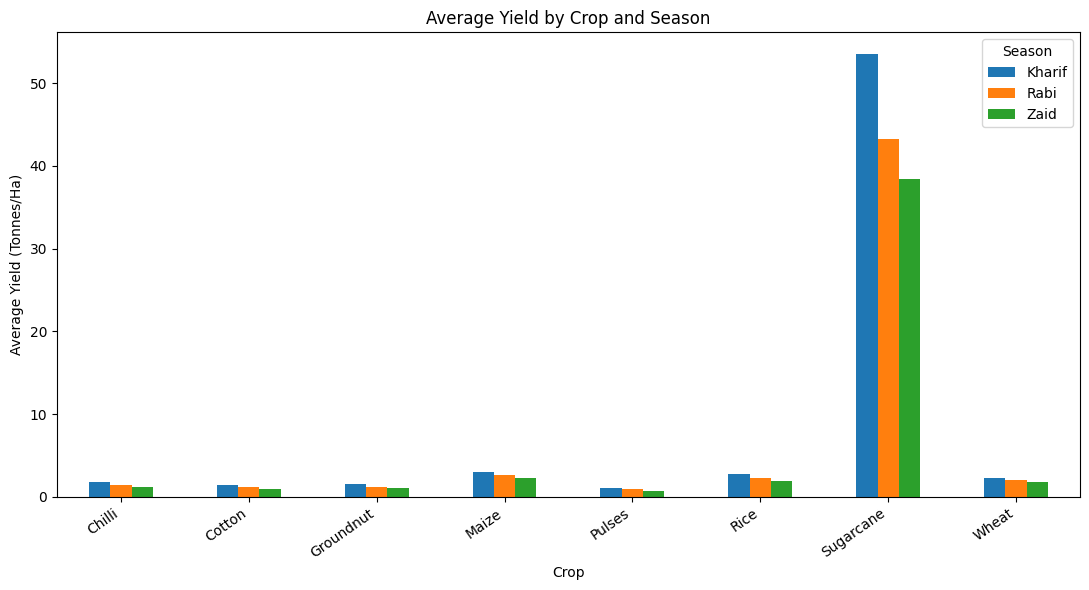

In [276]:
# Crop × Season grouped bar chart

crop_season_bar = df.pivot_table(
    index="Crop",
    columns="Season",
    values="Yield_Tonnes_Ha",
    aggfunc="mean"
)

crop_season_bar.plot(kind="bar", figsize=(11, 6))
plt.title("Average Yield by Crop and Season")
plt.xlabel("Crop")
plt.ylabel("Average Yield (Tonnes/Ha)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

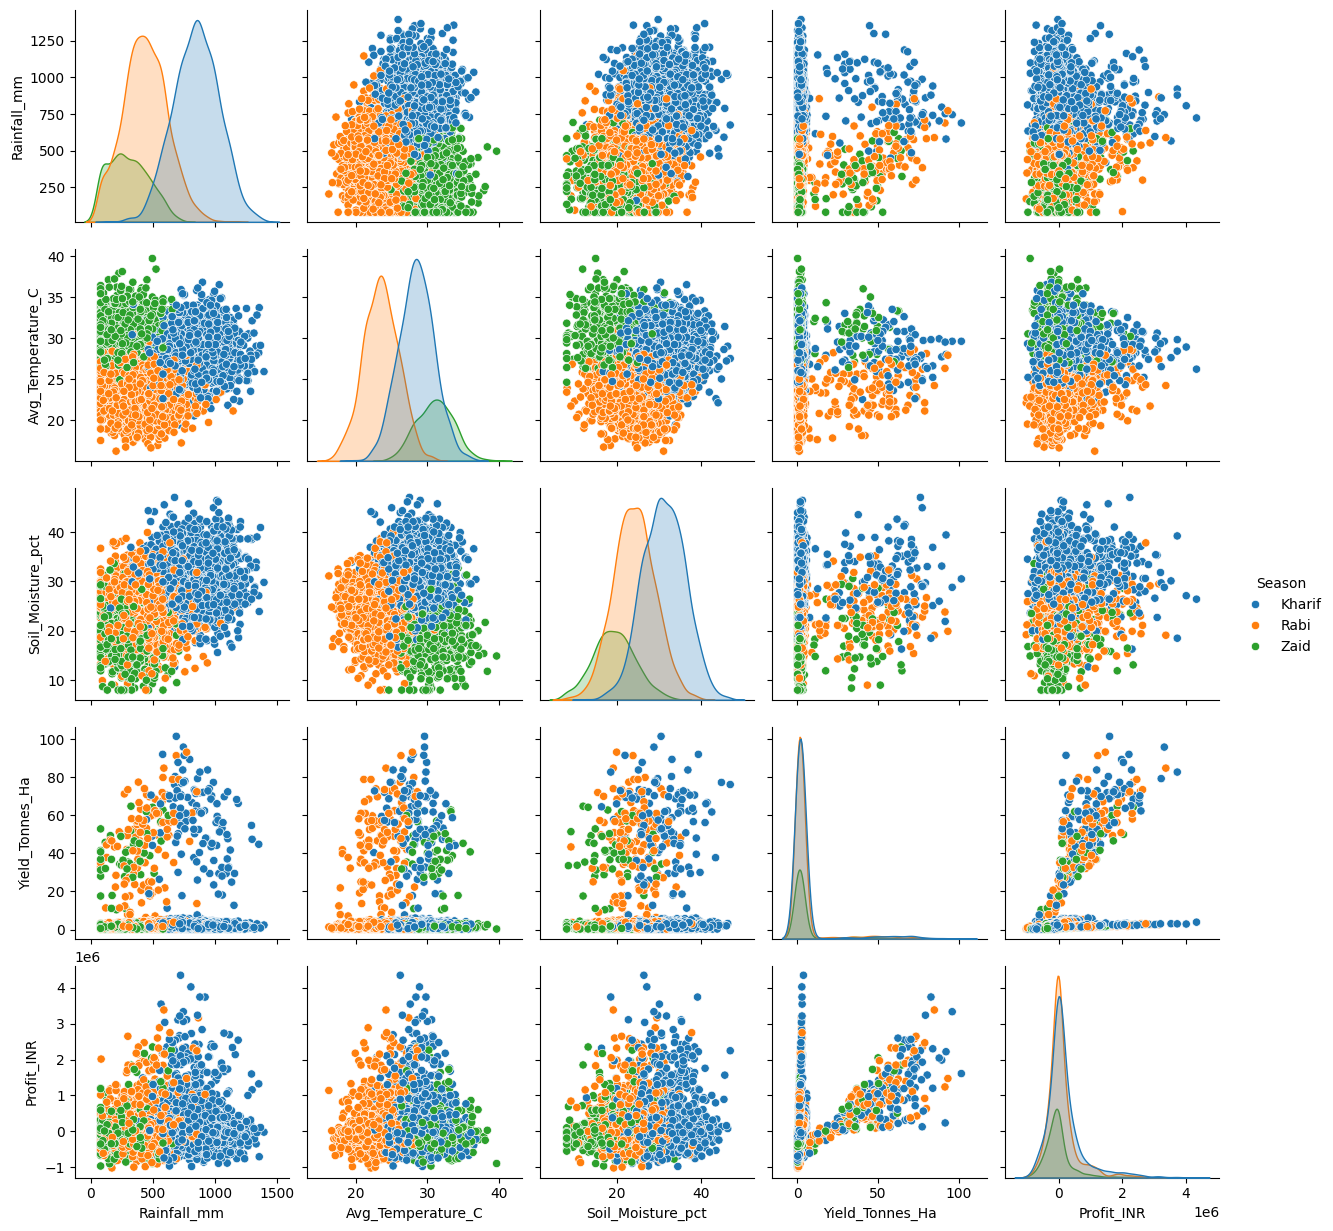

In [277]:
# Environmental and performance pairplot by season

pairplot_columns = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Soil_Moisture_pct",
    "Yield_Tonnes_Ha",
    "Profit_INR"
]

pairplot_columns = [col for col in pairplot_columns if col in df.columns]

sns.pairplot(
    df[pairplot_columns + ["Season"]],
    hue="Season"
)
plt.show()

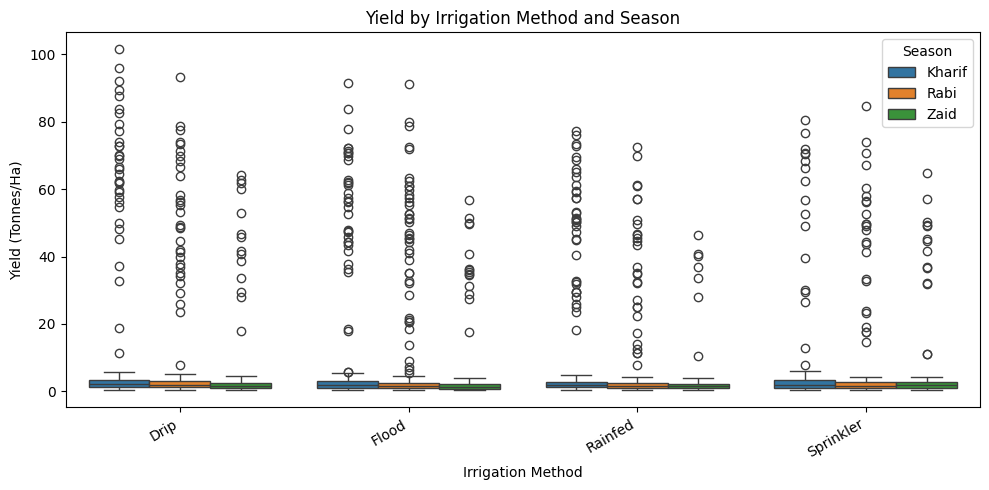

In [278]:
# Irrigation × Season yield

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="Irrigation_Method",
    y="Yield_Tonnes_Ha",
    hue="Season"
)
plt.title("Yield by Irrigation Method and Season")
plt.xlabel("Irrigation Method")
plt.ylabel("Yield (Tonnes/Ha)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

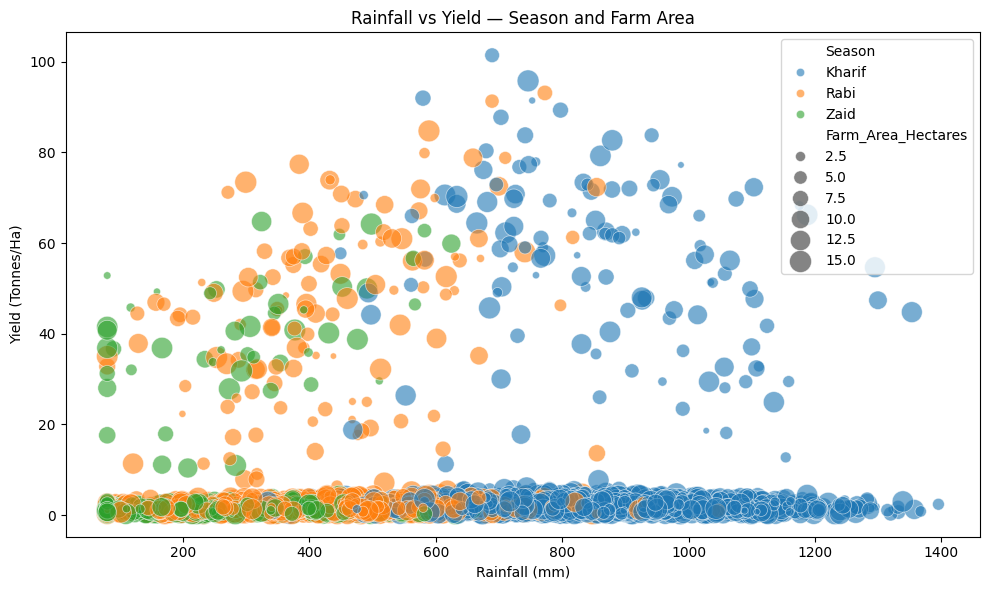

In [279]:
# Multivariate scatter: rainfall, yield, season and farm area

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Rainfall_mm",
    y="Yield_Tonnes_Ha",
    hue="Season",
    size="Farm_Area_Hectares",
    sizes=(20, 250),
    alpha=0.6
)
plt.title("Rainfall vs Yield — Season and Farm Area")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (Tonnes/Ha)")
plt.tight_layout()
plt.show()

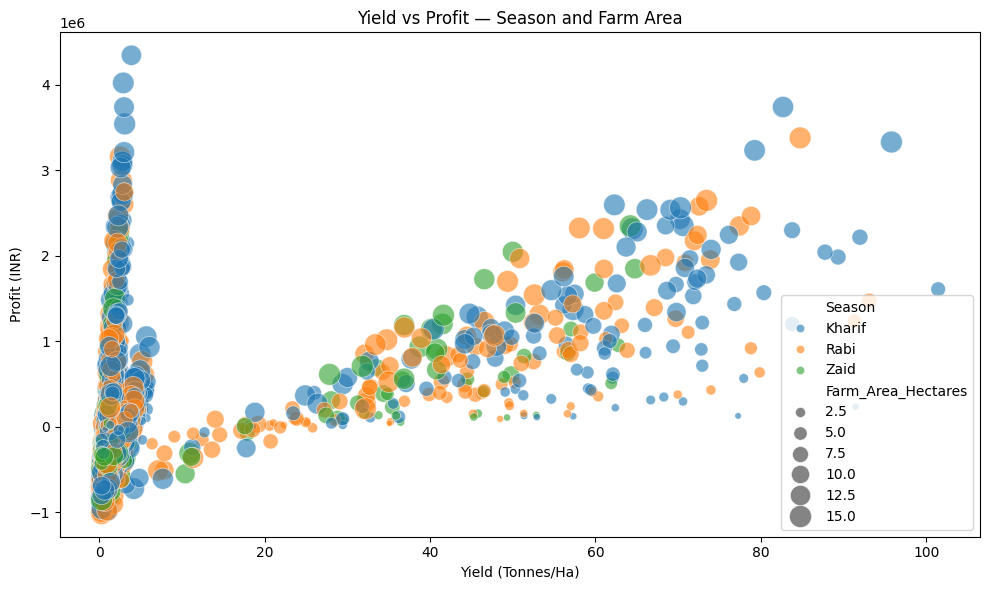

In [280]:
# Multivariate scatter: yield, profit, season and farm area

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Yield_Tonnes_Ha",
    y="Profit_INR",
    hue="Season",
    size="Farm_Area_Hectares",
    sizes=(20, 250),
    alpha=0.6
)
plt.title("Yield vs Profit — Season and Farm Area")
plt.xlabel("Yield (Tonnes/Ha)")
plt.ylabel("Profit (INR)")
plt.tight_layout()
plt.show()

## 14. Correlation Analysis

Pearson correlation is used to quantify linear association between numerical variables.

**Important:** correlation measures association, not causation.

,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
Rainfall_mm,1.000,0.198,0.521,-0.363,0.017,0.509,0.007,0.021,0.031,0.025,0.004,-0.019,0.031,0.001,0.013,0.098,0.108,0.002,0.058,0.622
Avg_Temperature_C,0.198,1.000,0.138,-0.034,0.030,0.084,0.019,0.009,0.023,0.016,0.007,-0.032,0.010,0.003,0.041,0.027,0.009,0.023,0.007,0.246
Humidity_pct,0.521,0.138,1.000,-0.297,0.028,0.446,0.001,-0.006,-0.003,0.025,-0.004,-0.046,0.012,0.000,0.006,0.057,0.064,-0.002,0.026,0.545
Sunlight_Hours_Day,-0.363,-0.034,-0.297,1.000,-0.018,-0.303,0.010,0.002,-0.014,-0.013,-0.017,0.021,-0.015,-0.001,-0.001,-0.047,-0.055,-0.006,-0.021,-0.253
Soil_pH,0.017,0.030,0.028,-0.018,1.000,0.031,0.006,0.017,-0.019,-0.011,-0.010,-0.004,-0.021,0.022,0.005,-0.009,-0.013,-0.023,-0.010,0.031
Soil_Moisture_pct,0.509,0.084,0.446,-0.303,0.031,1.000,0.009,0.013,0.008,0.009,-0.023,-0.020,0.011,0.017,0.003,0.079,0.091,0.003,0.028,0.376
Nitrogen_kg_ha,0.007,0.019,0.001,0.010,0.006,0.009,1.000,0.010,0.010,-0.032,0.014,0.015,0.053,-0.023,0.012,0.078,0.085,0.022,0.055,-0.012
Phosphorus_kg_ha,0.021,0.009,-0.006,0.002,0.017,0.013,0.010,1.000,0.003,0.013,-0.030,-0.008,0.048,-0.005,-0.017,0.035,0.050,-0.001,0.057,0.032
Potassium_kg_ha,0.031,0.023,-0.003,-0.014,-0.019,0.008,0.010,0.003,1.000,0.017,-0.005,0.007,0.003,0.008,0.003,0.028,0.031,0.002,0.007,0.013
Fertilizer_kg_ha,0.025,0.016,0.025,-0.013,-0.011,0.009,-0.032,0.013,0.017,1.000,-0.001,0.016,0.000,-0.001,0.147,0.005,-0.074,0.001,0.005,0.018


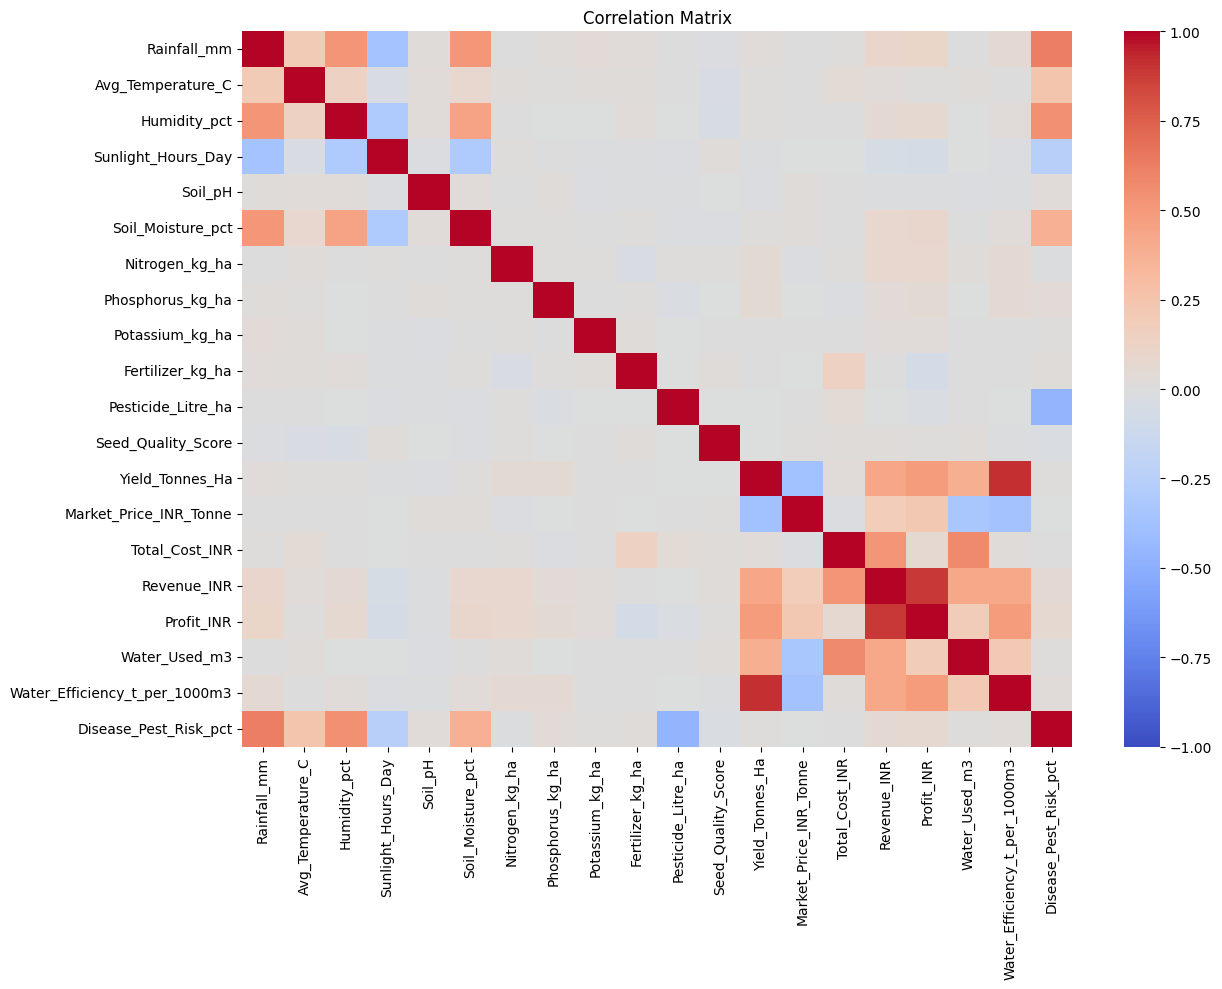

In [281]:
# Correlation matrix for relevant environmental, input and performance variables

corr_candidates = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Seed_Quality_Score",
    "Yield_Tonnes_Ha",
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Profit_INR",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Disease_Pest_Risk_pct"
]

corr_cols = [col for col in corr_candidates if col in df.columns]
corr = df[corr_cols].corr()

display(corr.round(3))

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr,
    center=0,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [282]:
# Correlation matrix

correlation_columns = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Seed_Quality_Score",
    "Yield_Tonnes_Ha",
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Profit_INR",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Disease_Pest_Risk_pct"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix.round(3)


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
Rainfall_mm,1.000,0.198,0.521,-0.363,0.017,0.509,0.007,0.021,0.031,0.025,0.004,-0.019,0.031,0.001,0.013,0.098,0.108,0.002,0.058,0.622
Avg_Temperature_C,0.198,1.000,0.138,-0.034,0.030,0.084,0.019,0.009,0.023,0.016,0.007,-0.032,0.010,0.003,0.041,0.027,0.009,0.023,0.007,0.246
Humidity_pct,0.521,0.138,1.000,-0.297,0.028,0.446,0.001,-0.006,-0.003,0.025,-0.004,-0.046,0.012,0.000,0.006,0.057,0.064,-0.002,0.026,0.545
Sunlight_Hours_Day,-0.363,-0.034,-0.297,1.000,-0.018,-0.303,0.010,0.002,-0.014,-0.013,-0.017,0.021,-0.015,-0.001,-0.001,-0.047,-0.055,-0.006,-0.021,-0.253
Soil_pH,0.017,0.030,0.028,-0.018,1.000,0.031,0.006,0.017,-0.019,-0.011,-0.010,-0.004,-0.021,0.022,0.005,-0.009,-0.013,-0.023,-0.010,0.031
Soil_Moisture_pct,0.509,0.084,0.446,-0.303,0.031,1.000,0.009,0.013,0.008,0.009,-0.023,-0.020,0.011,0.017,0.003,0.079,0.091,0.003,0.028,0.376
Nitrogen_kg_ha,0.007,0.019,0.001,0.010,0.006,0.009,1.000,0.010,0.010,-0.032,0.014,0.015,0.053,-0.023,0.012,0.078,0.085,0.022,0.055,-0.012
Phosphorus_kg_ha,0.021,0.009,-0.006,0.002,0.017,0.013,0.010,1.000,0.003,0.013,-0.030,-0.008,0.048,-0.005,-0.017,0.035,0.050,-0.001,0.057,0.032
Potassium_kg_ha,0.031,0.023,-0.003,-0.014,-0.019,0.008,0.010,0.003,1.000,0.017,-0.005,0.007,0.003,0.008,0.003,0.028,0.031,0.002,0.007,0.013
Fertilizer_kg_ha,0.025,0.016,0.025,-0.013,-0.011,0.009,-0.032,0.013,0.017,1.000,-0.001,0.016,0.000,-0.001,0.147,0.005,-0.074,0.001,0.005,0.018


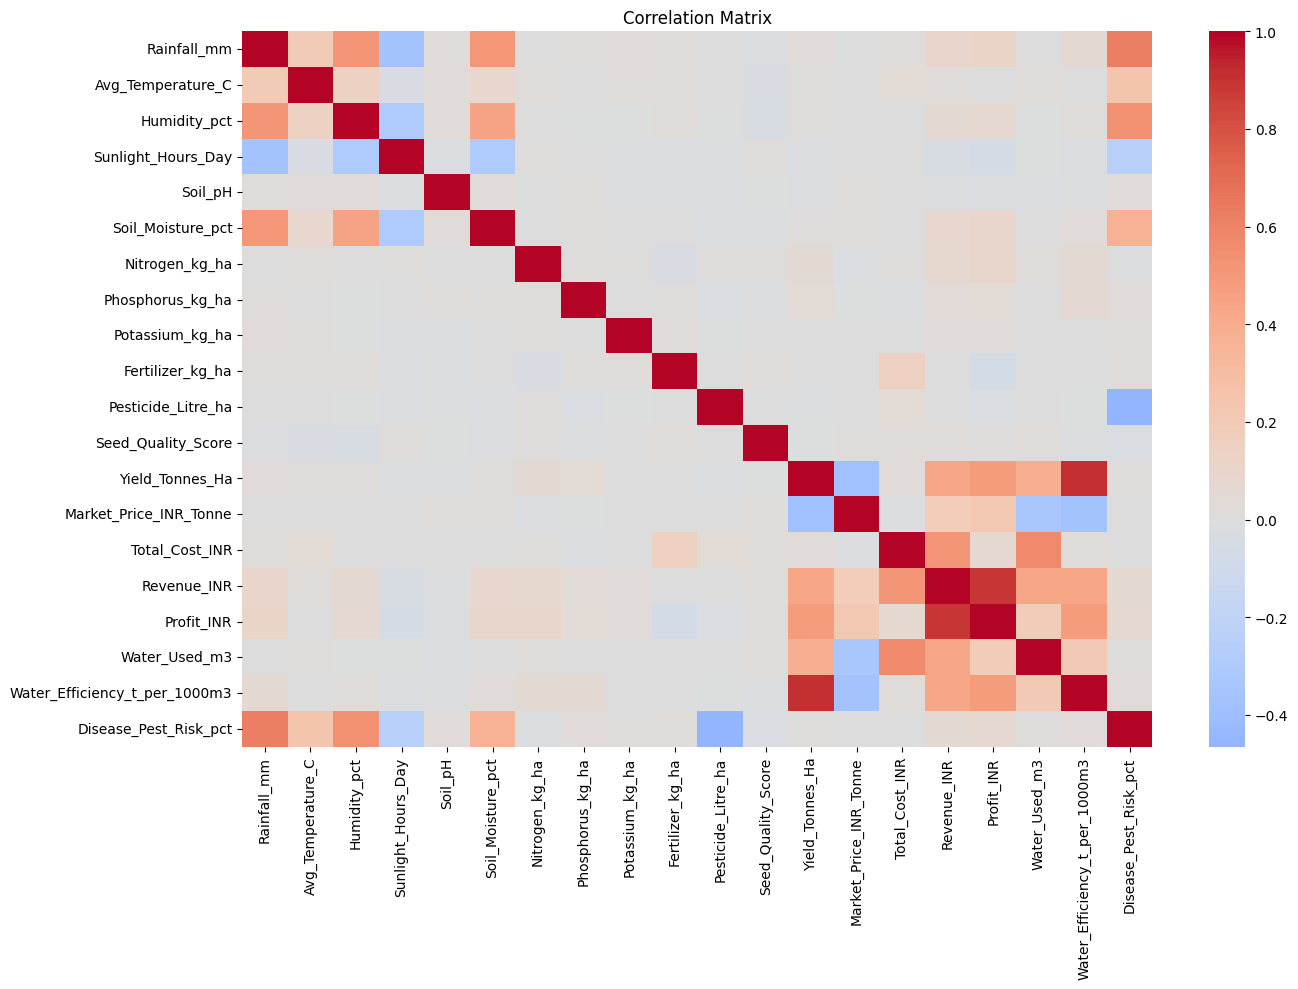

In [283]:
# Correlation heatmap

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


## 15. Seasonal Comparison

The project specifically requires comparison of agricultural performance across seasons.

The following measures are used:
- Average yield
- Total production
- Average profit
- Total profit
- Average water use
- Average water efficiency
- Average disease/pest risk


In [284]:
# Season-wise performance summary

season_metrics = df.groupby("Season").agg(
    Records=("Farm_ID", "count"),
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Total_Production=("Production_Tonnes", "sum"),
    Average_Profit=("Profit_INR", "mean"),
    Total_Profit=("Profit_INR", "sum"),
    Average_Water_Used=("Water_Used_m3", "mean"),
    Average_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Average_Risk=("Disease_Pest_Risk_pct", "mean")
).round(2)

season_metrics


,Records,Average_Yield,Total_Production,Average_Profit,Total_Profit,Average_Water_Used,Average_Water_Efficiency,Average_Risk
Season,,,,,,,,
Kharif,1779,5.63,82387.61,178914.65,318289158,6102.20,5.89,54.47
Rabi,1627,5.04,67498.88,87689.47,142670768,5846.99,5.19,40.48
Zaid,594,4.64,23098.35,-24804.82,-14734066,6419.89,4.41,38.22


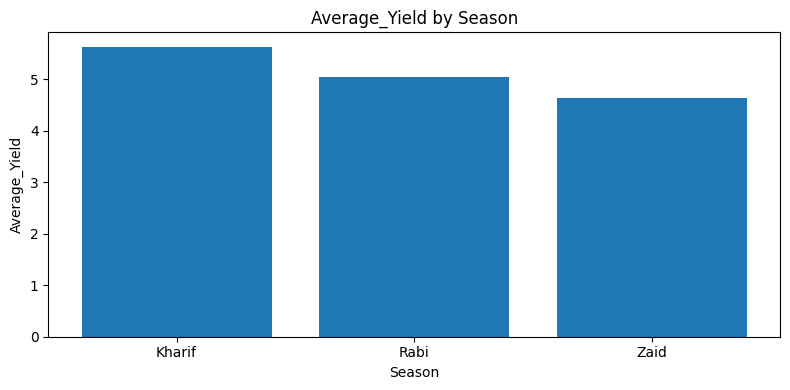

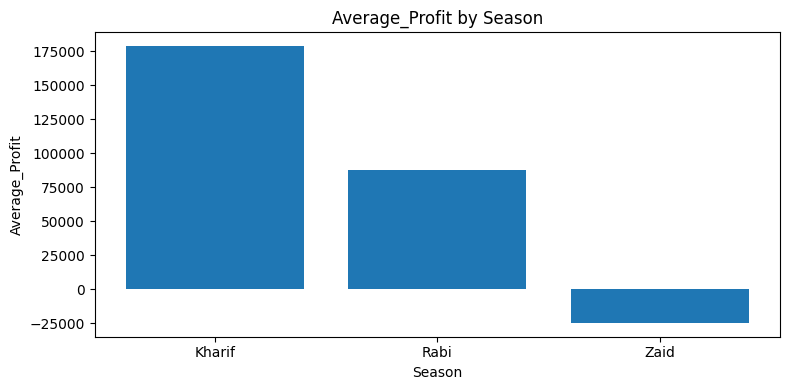

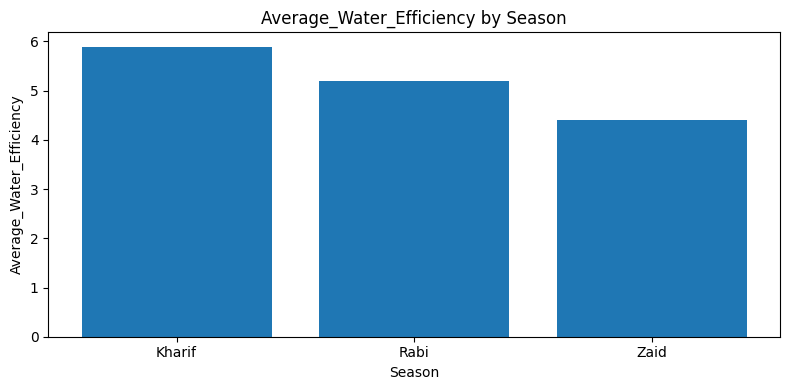

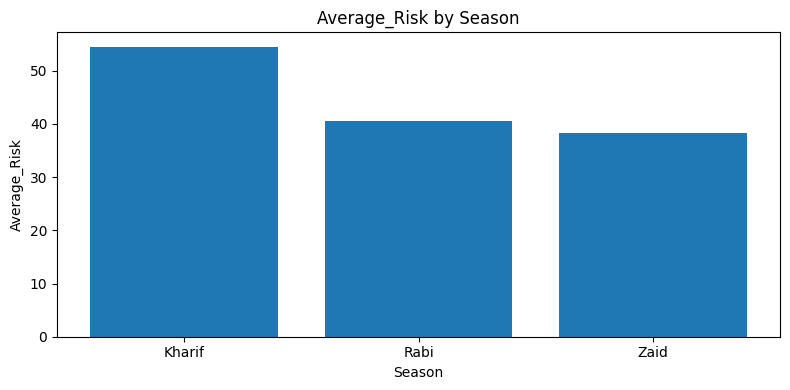

In [285]:
# Compare important seasonal measures

for metric in [
    "Average_Yield",
    "Average_Profit",
    "Average_Water_Efficiency",
    "Average_Risk"
]:
    values = season_metrics[metric].sort_values(ascending=False)

    plt.figure(figsize=(8, 4))
    plt.bar(values.index, values.values)
    plt.title(metric + " by Season")
    plt.ylabel(metric)
    plt.xlabel("Season")
    plt.tight_layout()
    plt.show()


## 16. Crop Performance Within Each Season

In [286]:
# Crop-level seasonal comparison

crop_season_summary.sort_values(
    ["Season", "Average_Yield"],
    ascending=[True, False]
)


Records  Average_Yield  Average_Profit  \
Season Crop                                                
Kharif Sugarcane      125          53.46      1000790.81   
       Maize          234           2.97       -39332.67   
       Rice           314           2.70       -64903.40   
       Wheat          292           2.25      -105871.87   
       Chilli         185           1.73       954380.42   
       Groundnut      193           1.48       108265.44   
       Cotton         215           1.37       216999.55   
       Pulses         221           1.04        43338.90   
Rabi   Sugarcane      129          43.29       731612.86   
       Maize          233           2.60       -89133.40   
       Rice           274           2.32       -98427.87   
       Wheat          237           2.06      -119954.57   
       Chilli         163           1.47       638572.50   
       Groundnut      177           1.23        10416.54   
       Cotton         201           1.20       107343.59   
       Pulses         213           0.88       -14309.14   
Zaid   Sugarcane       51          38.42       583635.80   
       Maize           84           2.29      -194049.17   
       Rice           102           1.90      -227239.34   
       Wheat           85           1.75      -193208.95   
       Chilli          64           1.20       448659.09   
       Groundnut       54           1.04       -68872.50   
       Cotton          92           0.96       -53925.34   
       Pulses          62           0.67      -139227.81   

                  Average_Water_Efficiency  Average_Risk  
Season Crop                                               
Kharif Sugarcane                     36.00         54.02  
       Maize                          6.05         54.82  
       Rice                           2.17         54.25  
       Wheat                          4.76         55.58  
       Chilli                         3.26         52.81  
       Groundnut                      3.58         54.28  
       Cotton                         2.13         54.24  
       Pulses                         3.35         54.96  
Rabi   Sugarcane                     27.92         39.85  
       Maize                          5.46         39.41  
       Rice                           1.84         40.79  
       Wheat                          4.69         41.46  
       Chilli                         2.89         40.59  
       Groundnut                      2.90         39.76  
       Cotton                         1.94         41.54  
       Pulses                         2.70         40.08  
Zaid   Sugarcane                     23.39         38.35  
       Maize                          4.75         36.68  
       Rice                           1.53         37.95  
       Wheat                          4.02         39.16  
       Chilli                         2.20         40.50  
       Groundnut                      2.47         39.13  
       Cotton                         1.49         36.34  
       Pulses                         1.95         38.97

In [287]:
# Highest-profit crop within each season

highest_profit_crop = (
    df.groupby(["Season", "Crop"])["Profit_INR"]
      .mean()
      .reset_index()
      .sort_values(["Season", "Profit_INR"], ascending=[True, False])
)

highest_profit_crop.groupby("Season").head(1)


,Season,Crop,Profit_INR
6,Kharif,Sugarcane,1.000791e+06
14,Rabi,Sugarcane,7.316129e+05
22,Zaid,Sugarcane,5.836358e+05


## 17. Profitability vs Water Efficiency

**Question:** Which crop-season combinations combine stronger profitability with better water efficiency?

This analysis connects economic performance with resource efficiency.


In [288]:
student_analysis_1 = df.groupby(["Season", "Crop"]).agg(
    Average_Profit=("Profit_INR", "mean"),
    Average_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Average_Yield=("Yield_Tonnes_Ha", "mean")
).round(2).sort_values("Average_Profit", ascending=False)

student_analysis_1


Average_Profit  Average_Water_Efficiency  Average_Yield
Season Crop                                                              
Kharif Sugarcane      1000790.81                     36.00          53.46
       Chilli          954380.42                      3.26           1.73
Rabi   Sugarcane       731612.86                     27.92          43.29
       Chilli          638572.50                      2.89           1.47
Zaid   Sugarcane       583635.80                     23.39          38.42
       Chilli          448659.09                      2.20           1.20
Kharif Cotton          216999.55                      2.13           1.37
       Groundnut       108265.44                      3.58           1.48
Rabi   Cotton          107343.59                      1.94           1.20
Kharif Pulses           43338.90                      3.35           1.04
Rabi   Groundnut        10416.54                      2.90           1.23
       Pulses          -14309.14                      2.70           0.88
Kharif Maize           -39332.67                      6.05           2.97
Zaid   Cotton          -53925.34                      1.49           0.96
Kharif Rice            -64903.40                      2.17           2.70
Zaid   Groundnut       -68872.50                      2.47           1.04
Rabi   Maize           -89133.40                      5.46           2.60
       Rice            -98427.87                      1.84           2.32
Kharif Wheat          -105871.87                      4.76           2.25
Rabi   Wheat          -119954.57                      4.69           2.06
Zaid   Pulses         -139227.81                      1.95           0.67
       Wheat          -193208.95                      4.02           1.75
       Maize          -194049.17                      4.75           2.29
       Rice           -227239.34                      1.53           1.90

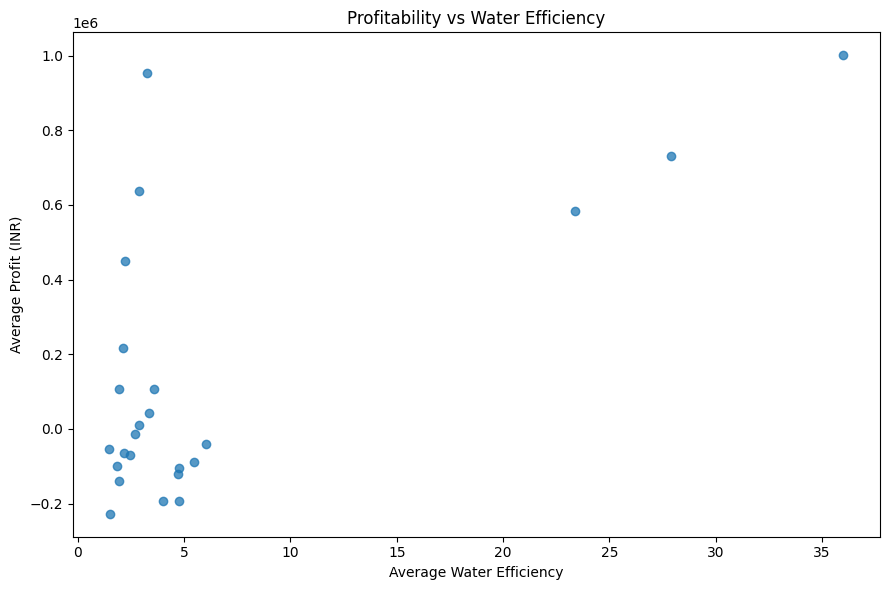

In [289]:
plt.figure(figsize=(9, 6))
plt.scatter(
    student_analysis_1["Average_Water_Efficiency"],
    student_analysis_1["Average_Profit"],
    alpha=0.75
)
plt.xlabel("Average Water Efficiency")
plt.ylabel("Average Profit (INR)")
plt.title("Profitability vs Water Efficiency")
plt.tight_layout()
plt.show()


## 18. Regional Performance

**Question:** Which states show stronger average agricultural performance?

This comparison helps identify differences between geographical groups.


In [290]:
state_summary = df.groupby("State").agg(
    Records=("Farm_ID", "count"),
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Average_Profit=("Profit_INR", "mean"),
    Average_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean")
).round(2).sort_values("Average_Profit", ascending=False)

state_summary


,Records,Average_Yield,Average_Profit,Average_Water_Efficiency
State,,,,
Punjab,484,6.12,136025.64,5.62
Maharashtra,512,5.02,135428.86,5.28
Karnataka,489,5.69,119422.34,5.56
Tamil Nadu,485,4.88,117744.75,5.31
Gujarat,488,5.66,117568.24,5.58
Telangana,516,5.04,108829.62,5.46
Madhya Pradesh,497,4.99,86840.76,5.27
Andhra Pradesh,529,4.63,73453.53,5.03


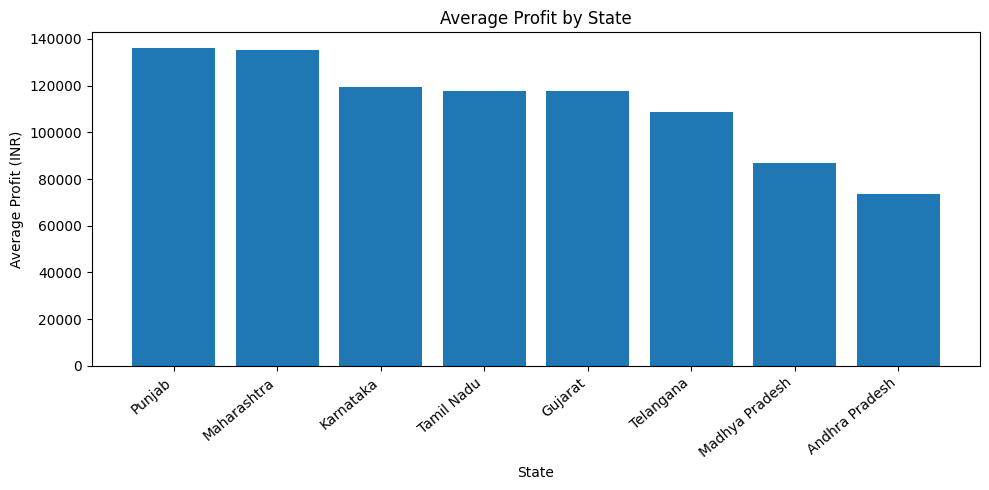

In [291]:
plt.figure(figsize=(10, 5))
plt.bar(state_summary.index, state_summary["Average_Profit"])
plt.title("Average Profit by State")
plt.ylabel("Average Profit (INR)")
plt.xlabel("State")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


## 19. Yield Consistency

**Question:** Which crop-season combinations have the highest relative variability in yield?

The coefficient of variation (CV) is used as a simple consistency indicator.


In [292]:
student_analysis_3 = df.groupby(["Season", "Crop"])["Yield_Tonnes_Ha"].agg(
    Average_Yield="mean",
    Yield_Std="std",
    Records="count"
)

student_analysis_3["Yield_CV_%"] = (
    student_analysis_3["Yield_Std"] /
    student_analysis_3["Average_Yield"].replace(0, np.nan)
) * 100

student_analysis_3 = student_analysis_3.round(2).sort_values(
    "Yield_CV_%",
    ascending=False
)

student_analysis_3.head(15)


Average_Yield  Yield_Std  Records  Yield_CV_%
Season Crop                                                    
Rabi   Chilli              1.47       0.72      163       49.47
       Sugarcane          43.29      21.27      129       49.13
Kharif Chilli              1.73       0.84      185       48.52
Zaid   Pulses              0.67       0.32       62       48.47
       Chilli              1.20       0.57       64       47.67
Kharif Rice                2.70       1.24      314       46.01
Zaid   Groundnut           1.04       0.48       54       45.82
Kharif Maize               2.97       1.36      234       45.81
Rabi   Rice                2.32       1.05      274       45.17
Zaid   Cotton              0.96       0.43       92       44.91
Rabi   Groundnut           1.23       0.55      177       44.47
Kharif Pulses              1.04       0.46      221       44.11
Rabi   Maize               2.60       1.14      233       43.69
Kharif Wheat               2.25       0.98      292       43.60
       Groundnut           1.48       0.64      193       43.33

## 20. Key Insights

The following cells generate evidence-based observations directly from the dataset rather than using invented numbers.


In [293]:
# Insight 1: strongest and weakest season by average yield

strongest_yield_season = season_metrics["Average_Yield"].idxmax()
weakest_yield_season = season_metrics["Average_Yield"].idxmin()

print("Highest average yield season:", strongest_yield_season)
print("Lowest average yield season:", weakest_yield_season)


Highest average yield season: Kharif
Lowest average yield season: Zaid


In [294]:
# Insight 2: strongest and weakest season by average profit

strongest_profit_season = season_metrics["Average_Profit"].idxmax()
weakest_profit_season = season_metrics["Average_Profit"].idxmin()

print("Highest average profit season:", strongest_profit_season)
print("Lowest average profit season:", weakest_profit_season)


Highest average profit season: Kharif
Lowest average profit season: Zaid


In [295]:
# Insight 3: highest and lowest water efficiency season

highest_efficiency_season = season_metrics["Average_Water_Efficiency"].idxmax()
lowest_efficiency_season = season_metrics["Average_Water_Efficiency"].idxmin()

print("Highest water efficiency season:", highest_efficiency_season)
print("Lowest water efficiency season:", lowest_efficiency_season)


Highest water efficiency season: Kharif
Lowest water efficiency season: Zaid


In [296]:
# Insight 4: highest and lowest average-risk season

highest_risk_season = season_metrics["Average_Risk"].idxmax()
lowest_risk_season = season_metrics["Average_Risk"].idxmin()

print("Highest average disease/pest risk season:", highest_risk_season)
print("Lowest average disease/pest risk season:", lowest_risk_season)


Highest average disease/pest risk season: Kharif
Lowest average disease/pest risk season: Zaid


In [297]:
# Insight 5: most profitable crop overall

most_profitable_crop = df.groupby("Crop")["Profit_INR"].mean().idxmax()
most_profitable_crop_value = df.groupby("Crop")["Profit_INR"].mean().max()

print("Most profitable crop:", most_profitable_crop)
print("Average profit:", round(most_profitable_crop_value, 2))


Most profitable crop: Sugarcane
Average profit: 817187.99


In [298]:
# Insight 6: highest-yield crop overall

highest_yield_crop = df.groupby("Crop")["Yield_Tonnes_Ha"].mean().idxmax()
highest_yield_value = df.groupby("Crop")["Yield_Tonnes_Ha"].mean().max()

print("Highest average-yield crop:", highest_yield_crop)
print("Average yield:", round(highest_yield_value, 2))


Highest average-yield crop: Sugarcane
Average yield: 46.64


In [299]:
# Insight 7: relationship between yield and profit

yield_profit_correlation = df["Yield_Tonnes_Ha"].corr(df["Profit_INR"])

print("Correlation between yield and profit:", round(yield_profit_correlation, 3))


Correlation between yield and profit: 0.488


In [300]:
# Insight 8: share of loss-making records

loss_making_percentage = (df["Profit_INR"] < 0).mean() * 100

print("Percentage of loss-making records:", round(loss_making_percentage, 2), "%")


Percentage of loss-making records: 49.15 %


### Interpretation of Key Insights

The analysis shows differences in agricultural performance across seasons, crops and regions. The strongest and weakest seasons can be identified using average yield, profitability, water efficiency and disease/pest risk. Crop-level results further highlight differences in yield and profitability, while the yield-profit correlation indicates the strength of their observed association. The percentage of loss-making records also provides an indication of overall profitability risk in the dataset.

## 21. Evidence-Based Recommendations

Recommendations should follow the observed results rather than assume causation.

1. Compare seasonal performance before planning crop allocation or resource use.
2. Investigate crop-season combinations with consistently strong profitability and water efficiency.
3. Review crop-season groups with high yield variability for possible operational differences.
4. Pay attention to seasons or regions with relatively high disease/pest risk.
5. Use high-performing crop and regional groups as benchmarks for further investigation.
6. Improve future data collection by recording more detailed cost, selling-price, irrigation-cost, soil, rainfall-timing, pest-severity and historical-year information.

> These recommendations describe how the findings can support planning and further investigation; they do not claim that any single variable causes an outcome.


## 22. Limitations and Conclusion

### Limitations

1. The dataset is observational, so associations cannot be interpreted as causal effects.
2. The available data represents a finite sample and should not automatically be treated as a complete multi-year time series.
3. Some explanatory variables may be missing or simplified.
4. Different crops may naturally operate at different yield scales.
5. Outliers may represent legitimate agricultural variation and were therefore investigated rather than automatically removed.
6. Additional statistical testing and multi-year validation would strengthen high-stakes decisions.

### Conclusion

The analysis shows clear differences in agricultural performance across seasons, crops and regions. Seasonal comparisons indicate that **Kharif is the strongest overall season**, with the highest observed average yield, profitability and water efficiency, while **Zaid shows weaker profitability and a higher share of loss-making records**.

Crop-level analysis shows that performance varies across crops within each season. **Sugarcane performs strongly across yield, profit and water efficiency**, while some crop-season combinations show lower profitability or greater yield variability and therefore require further investigation.

The analysis also identifies noticeable differences in **water use and water efficiency** across seasons, crops and irrigation groups. These differences show that higher resource use does not necessarily indicate better efficiency, making water efficiency an important measure alongside yield and profitability.

Relationship analysis shows a **moderate positive association between yield and profit**, indicating that higher yield is generally associated with higher profit in the observed data. Environmental and resource variables such as rainfall, water use and input usage also show relationships with agricultural outcomes, although these relationships should be interpreted as associations rather than causal effects.

The crop-season analysis highlights combinations with unusually high or low yield, profitability and variability. **Profitability risk is particularly visible in loss-making records and weaker-performing seasonal or crop-season groups**, which can be used as areas for further investigation.

Overall, this project demonstrates how data analysis can be used to compare seasonal performance, evaluate crop-season differences, examine resource efficiency, identify relationships and highlight profitability risks. The findings can support **benchmarking and further investigation**, while additional multi-year, cost, price, environmental and farm-level data would help provide stronger and more detailed conclusions.